In [68]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import netCDF4 as nc4
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature



In [69]:
ca_folder = r"D:\Final_Project_Data\Chlorophyll_a"
ca_file = os.path.join(ca_folder, "WCS1367115429627925921.nc")

ds = nc4.Dataset(ca_file)

print(ds)

print(os.listdir(ca_folder))
# Reopen the corrected file
ds = nc4.Dataset(ca_file)

# Check coordinate ranges
print("Latitude:", ds.variables["lat"][:].min(),
      "to", ds.variables["lat"][:].max())

print("Longitude:", ds.variables["lon"][:].min(),
      "to", ds.variables["lon"][:].max())

print("\nChlorophyll variable:")
print(ds.variables["chlor_a"])

<class 'netCDF4.Dataset'>
root group (NETCDF3_CLASSIC data model, file format NETCDF3):
    Conventions: CF-1.7
    Metadata_Conventions: Unidata Dataset Discovery v1.0
    cdm_data_type: Grid
    comment: See summary attribute
    creator_email: help@esa-oceancolour-cci.org
    creator_name: Plymouth Marine Laboratory
    creator_url: http://esa-oceancolour-cci.org
    geospatial_lat_max: -10.020833333333329
    geospatial_lat_min: -20.02083333333333
    geospatial_lat_resolution: .04166666666666666666
    geospatial_lat_units: decimal degrees north
    geospatial_lon_max: -69.97916666666667
    geospatial_lon_min: -79.97916666666667
    geospatial_lon_resolution: .04166666666666666666
    geospatial_lon_units: decimal degrees east
    geospatial_vertical_max: 0.0
    geospatial_vertical_min: 0.0
    git_commit_hash: 03a84c0d1f5d4230f3355876add4bafc0f99a1d4
    institution: Plymouth Marine Laboratory
    keywords: satellite,observation,ocean,ocean colour
    keywords_vocabulary: none


In [70]:

# Convert numeric time values into dates
dates = nc4.num2date(
    time_var[:],
    units=time_var.units,
    calendar=getattr(time_var, "calendar", "standard"),
    only_use_cftime_datetimes=False)


In [71]:
# Get latitude and longitude
lat_h = ds.variables["lat"][:]
lon_h = ds.variables["lon"][:]

# Define the Humboldt study region
lat_min_h, lat_max_h = -20, -10
lon_min_h, lon_max_h = -80, -70

# Find the indices within our study region
lat_indices_h = np.where((lat_h >= lat_min_h) & (lat_h <= lat_max_h))[0]
lon_indices_h = np.where((lon_h >= lon_min_h) & (lon_h <= lon_max_h))[0]

# Extract chlorophyll-a data
chlor_a_h = ds.variables["chlor_a"][:, lat_indices_h, :][:, :, lon_indices_h]

In [72]:
# Convert masked values to NaN
chlor_a_data_h = np.ma.filled(chlor_a_h, np.nan).astype(float)

# Exclude zero and negative chlorophyll values
chlor_a_data_h[chlor_a_data_h <= 0] = np.nan

# Calculate latitude weights (cosine of latitude)
weights_h = np.cos(np.deg2rad(lat_h[lat_indices_h]))
weights_h = weights_h[np.newaxis, :, np.newaxis]

# Calculate weighted regional mean for each month
valid_weights_h = np.isfinite(chlor_a_data_h) * weights_h

monthly_chla_h = (
    np.nansum(chlor_a_data_h * weights_h, axis=(1, 2)) /
    np.sum(valid_weights_h, axis=(1, 2)))

print("Number of monthly averages:", len(monthly_chla_h))
print("Minimum:", np.nanmin(monthly_chla_h), "mg m-3")
print("Maximum:", np.nanmax(monthly_chla_h), "mg m-3")
print("Mean:", np.nanmean(monthly_chla_h), "mg m-3")

Number of monthly averages: 285
Minimum: 0.4679244634939472 mg m-3
Maximum: 1.692464740203407 mg m-3
Mean: 0.8777646588092674 mg m-3


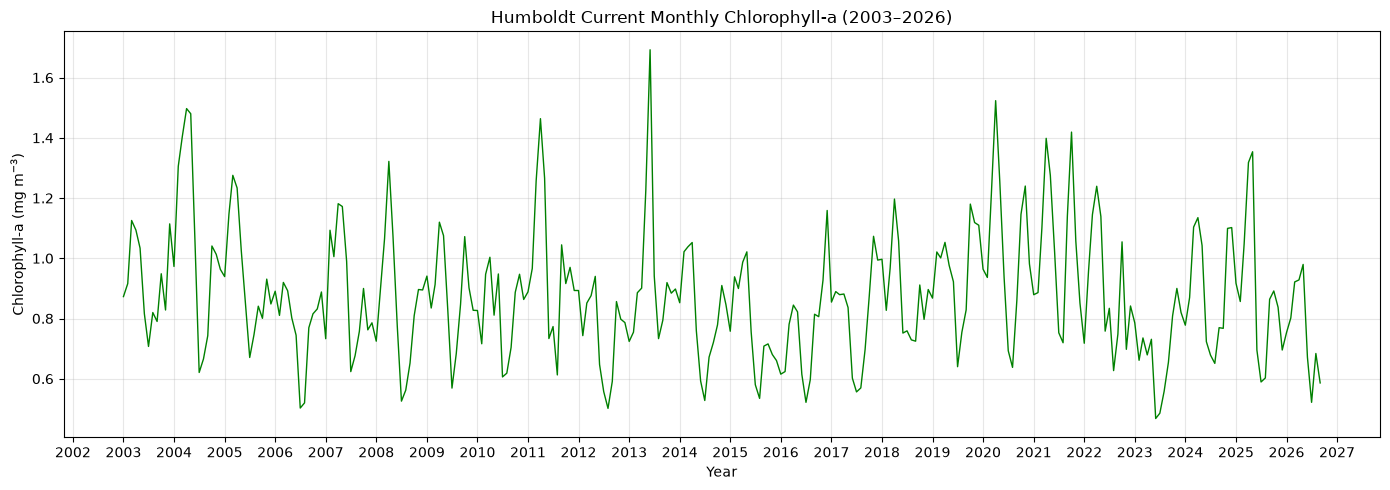

In [73]:
plt.figure(figsize=(14, 5))

plt.plot(dates, monthly_chla, color="green", linewidth=1)

plt.title("Humboldt Current Monthly Chlorophyll-a (2003–2026)")
plt.xlabel("Year")
plt.ylabel("Chlorophyll-a (mg m$^{-3}$)")
plt.grid(True, alpha=0.3)

# Set x-axis labels to January of each year
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

In [74]:
ca_folder = r"D:\Final_Project_Data\Chlorophyll_a"
ca_file = os.path.join(ca_folder, "WCS4140673200432282821.nc")

ds_c = nc4.Dataset(ca_file)

print(ds_c)

print(os.listdir(ca_folder))
# Reopen the corrected file
ds_c = nc4.Dataset(ca_file)

# Check coordinate ranges
print("Latitude:", ds.variables["lat"][:].min(),
      "to", ds.variables["lat"][:].max())

print("Longitude:", ds.variables["lon"][:].min(),
      "to", ds.variables["lon"][:].max())

print("\nChlorophyll variable:")
print(ds.variables["chlor_a"])

<class 'netCDF4.Dataset'>
root group (NETCDF3_CLASSIC data model, file format NETCDF3):
    Conventions: CF-1.7
    Metadata_Conventions: Unidata Dataset Discovery v1.0
    cdm_data_type: Grid
    comment: See summary attribute
    creator_email: help@esa-oceancolour-cci.org
    creator_name: Plymouth Marine Laboratory
    creator_url: http://esa-oceancolour-cci.org
    geospatial_lat_max: 29.97916666666667
    geospatial_lat_min: 19.97916666666667
    geospatial_lat_resolution: .04166666666666666666
    geospatial_lat_units: decimal degrees north
    geospatial_lon_max: -9.979166666666686
    geospatial_lon_min: -19.979166666666686
    geospatial_lon_resolution: .04166666666666666666
    geospatial_lon_units: decimal degrees east
    geospatial_vertical_max: 0.0
    geospatial_vertical_min: 0.0
    git_commit_hash: 03a84c0d1f5d4230f3355876add4bafc0f99a1d4
    institution: Plymouth Marine Laboratory
    keywords: satellite,observation,ocean,ocean colour
    keywords_vocabulary: none
  

In [75]:
# Convert numeric time values into dates
dates = nc4.num2date(
    time_var[:],
    units=time_var.units,
    calendar=getattr(time_var, "calendar", "standard"),
    only_use_cftime_datetimes=False)

In [76]:
# Get latitude and longitude
lat = ds_c.variables["lat"][:]
lon = ds_c.variables["lon"][:]

# Define the Humboldt study region
lat_min, lat_max = 20, 30
lon_min, lon_max = -20, -10

# Find the indices within our study region
lat_indices = np.where((lat >= lat_min) & (lat <= lat_max))[0]
lon_indices = np.where((lon >= lon_min) & (lon <= lon_max))[0]

# Extract chlorophyll-a data
chlor_a_c = ds_c.variables["chlor_a"][:, lat_indices, :][:, :, lon_indices]

In [77]:
chlor_a_data_c = np.ma.filled(chlor_a, np.nan).astype(float)

# Exclude zero and negative chlorophyll values
chlor_a_data_c[chlor_a_data_c <= 0] = np.nan

# Calculate latitude weights (cosine of latitude)
weights = np.cos(np.deg2rad(lat[lat_indices]))
weights = weights[np.newaxis, :, np.newaxis]

# Calculate weighted regional mean for each month
valid_weights = np.isfinite(chlor_a_data_c) * weights

monthly_chla_c = (
    np.nansum(chlor_a_data_c * weights, axis=(1, 2)) /
    np.sum(valid_weights, axis=(1, 2))
)

print("Number of monthly averages:", len(monthly_chla))
print("Minimum:", np.nanmin(monthly_chla), "mg m-3")
print("Maximum:", np.nanmax(monthly_chla), "mg m-3")
print("Mean:", np.nanmean(monthly_chla), "mg m-3")

Number of monthly averages: 285
Minimum: 0.4679244634939472 mg m-3
Maximum: 1.692464740203407 mg m-3
Mean: 0.8777646588092674 mg m-3


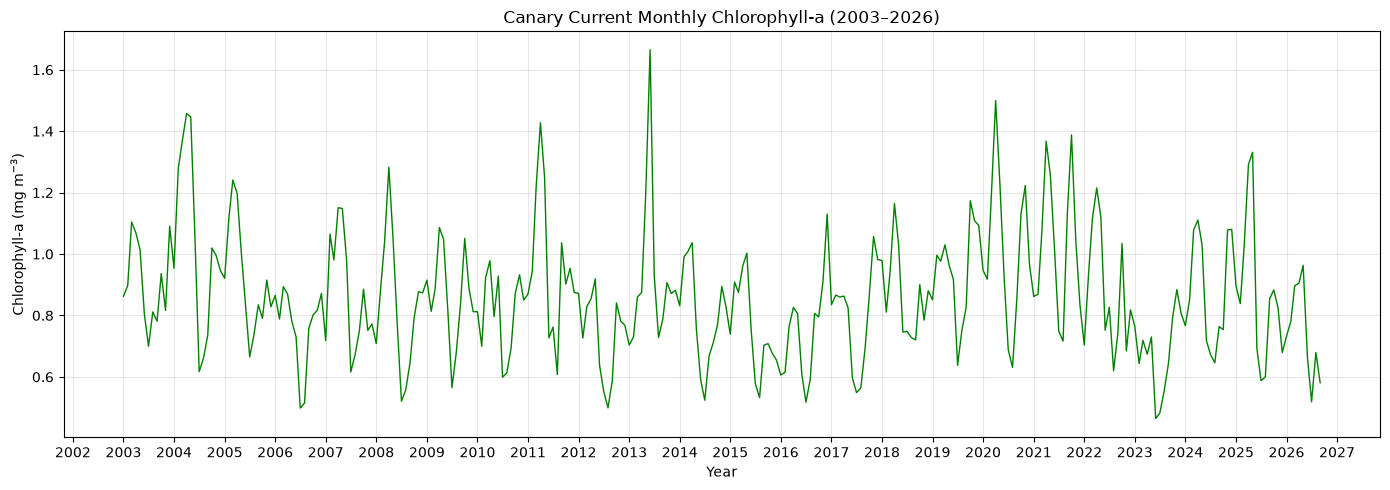

In [78]:
plt.figure(figsize=(14, 5))

plt.plot(dates, monthly_chla_c, color="green", linewidth=1)

plt.title("Canary Current Monthly Chlorophyll-a (2003–2026)")
plt.xlabel("Year")
plt.ylabel("Chlorophyll-a (mg m$^{-3}$)")
plt.grid(True, alpha=0.3)

# Set x-axis labels to January of each year
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

In [79]:
# Get the time variable from the Canary dataset
time_var_c = ds_c.variables["time"]

# Convert numeric time values into dates
dates_c = nc4.num2date(
    time_var_c[:],
    units=time_var_c.units,
    calendar=getattr(time_var_c, "calendar", "standard"),
    only_use_cftime_datetimes=False
)

print("First date:", dates_c[0])
print("Last date:", dates_c[-1])
print("Number of dates:", len(dates_c))

First date: 2003-01-01 00:00:00
Last date: 2026-09-01 00:00:00
Number of dates: 285


In [80]:
target_date = "2015-11"

date_strings_c = [
    date.strftime("%Y-%m") for date in dates_c
]

month_index_c = date_strings_c.index(target_date)

print("Month index:", month_index_c)
print("Selected date:", dates_c[month_index_c])

Month index: 154
Selected date: 2015-11-01 00:00:00


In [81]:
# Extract November 2015 chlorophyll-a
nov_chla_c = chlor_a_data_c[month_index_c, :, :]

print("Map shape:", nov_chla_c.shape)
print("Minimum:", np.nanmin(nov_chla_c))
print("Maximum:", np.nanmax(nov_chla_c))

Map shape: (240, 240)
Minimum: 0.04846217483282089
Maximum: 35.70627212524414


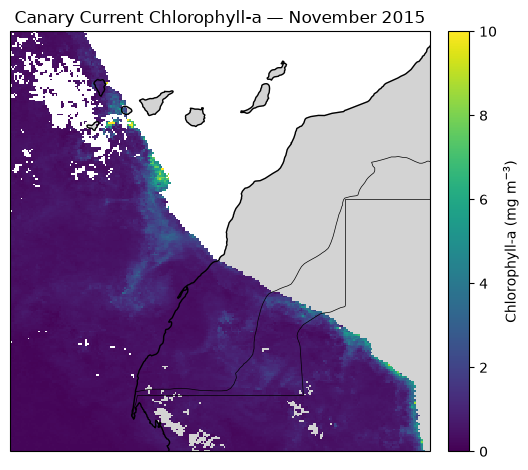

In [82]:
ax = plt.axes(projection=ccrs.PlateCarree())

# Plot chlorophyll-a
mesh = ax.pcolormesh(
    lon_c[lon_indices_c],
    lat_c[lat_indices_c],
    nov_chla_c,
    transform=ccrs.PlateCarree(),
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=10
)

# Add geographic features
ax.coastlines()
ax.add_feature(cfeature.LAND, color="lightgray")
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Set map boundaries
ax.set_extent([-20, -10, 20, 30], crs=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(mesh, ax=ax, orientation="vertical", pad=0.03)
cbar.set_label("Chlorophyll-a (mg m$^{-3}$)")

ax.set_title("Canary Current Chlorophyll-a — November 2015")

plt.tight_layout()
plt.show()

In [54]:
# Define Humboldt study region
lat_min_h, lat_max_h = -20, -10
lon_min_h, lon_max_h = -80, -70

# Find Humboldt indices
lat_indices_h = np.where(
    (lat_h >= lat_min_h) & (lat_h <= lat_max_h)
)[0]

lon_indices_h = np.where(
    (lon_h >= lon_min_h) & (lon_h <= lon_max_h)
)[0]

print("Humboldt latitude:", lat_h.min(), "to", lat_h.max())
print("Humboldt longitude:", lon_h.min(), "to", lon_h.max())
print("Selected latitude points:", len(lat_indices_h))
print("Selected longitude points:", len(lon_indices_h))

NameError: name 'lat_h' is not defined

In [67]:
date_strings_h = [
    date.strftime("%Y-%m") for date in dates
]

month_index = date_strings.index("2015-11")

# Extract November 2015 Humboldt chlorophyll-a
nov_chla = chlor_a_data[month_index, :, :]


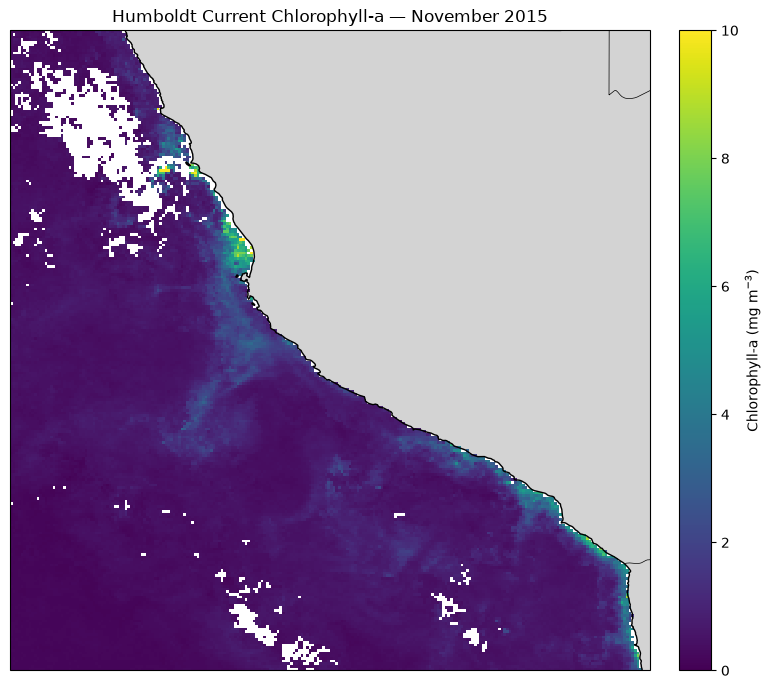

In [62]:
plt.figure(figsize=(10, 7))

ax = plt.axes(projection=ccrs.PlateCarree())

# Plot Humboldt chlorophyll-a
mesh = ax.pcolormesh(
    lon_h[lon_indices_h],
    lat_h[lat_indices_h],
    nov_chla,
    transform=ccrs.PlateCarree(),
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=10
)

# Add geographic features
ax.coastlines()
ax.add_feature(cfeature.LAND, color="lightgray")
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Set Humboldt map boundaries
ax.set_extent([-80, -70, -20, -10],
              crs=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(mesh, ax=ax, orientation="vertical", pad=0.03)
cbar.set_label("Chlorophyll-a (mg m$^{-3}$)")

ax.set_title("Humboldt Current Chlorophyll-a — November 2015")

plt.tight_layout()
plt.show()